# 1. Setup

In [5]:
import os
import glob
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torchvision import transforms
from torchvision.transforms import functional as TF
from PIL import Image
from transformers import AutoModelForImageClassification
import matplotlib.pyplot as plt

DATA_ROOT = "/Users/Jakub/Desktop/School/VISAI/hagrid-sample-30k-384p/hagrid_30k"
METADATA_CSV = "/Users/Jakub/Desktop/AI-VIS/phase1-Ai/split_preprocess-train/base results and setup/test_set_merged.csv"
MODEL_PATH = "/Users/Jakub/Desktop/AI-VIS/phase1-Ai/split_preprocess-train/model"   # or "best_model" depending on which notebook produced it
CLASSES = ["call", "dislike", "fist", "four", "like"]
BATCH_SIZE = 32
BRIGHTNESS_FACTOR = 1.8

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

cpu


# 2. Load trained model and original metadata

In [6]:
model = AutoModelForImageClassification.from_pretrained(MODEL_PATH).to(device)
model.eval()

meta = pd.read_csv(METADATA_CSV)

def find_path(img_id, label):
    pattern = os.path.join(DATA_ROOT, f"train_val_{label}", f"{img_id}.*")
    matches = glob.glob(pattern)
    return matches[0] if matches else None

meta["path"] = meta.apply(lambda r: find_path(r["id"], r["true_label"]), axis=1)
missing = meta["path"].isna().sum()
print("missing files:", missing)
meta = meta.dropna(subset=["path"]).reset_index(drop=True)

missing files: 0


# 3. Transform functions (each applied independently, no combinations)

In [16]:
def flip_upside_down(img):
    return img.transpose(Image.FLIP_TOP_BOTTOM)

def to_black_and_white(img):
    return TF.to_grayscale(img, num_output_channels=3)

def raise_brightness(img):
    return TF.adjust_brightness(img, BRIGHTNESS_FACTOR)

def flip_horizontal(img):
    return img.transpose(Image.TRANSPOSE)

def flip_90(img):
    return img.transpose(Image.ROTATE_90)


to_tensor_normalize = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

def preprocess_image(path, transform_fn):
    img = Image.open(path).convert("RGB")
    img = transform_fn(img)
    return to_tensor_normalize(img)

# 4. Run inference for one transform, return results dataframe

In [17]:
label2id = {l: i for i, l in enumerate(CLASSES)}

def run_inference(df, transform_fn):
    all_probs = []
    paths = df["path"].tolist()
    for i in range(0, len(paths), BATCH_SIZE):
        batch_paths = paths[i:i + BATCH_SIZE]
        pixel_values = torch.stack([preprocess_image(p, transform_fn) for p in batch_paths]).to(device)
        with torch.no_grad():
            logits = model(pixel_values=pixel_values).logits
            probs = F.softmax(logits, dim=1).cpu().numpy()
        all_probs.append(probs)
    all_probs = np.concatenate(all_probs, axis=0)

    result = df[["id", "true_label", "leading_hand", "leading_conf", "age", "race", "gender"]].copy()
    for i, cls in enumerate(CLASSES):
        result[f"prob_{cls}"] = all_probs[:, i]
    result["pred_label"] = [CLASSES[i] for i in all_probs.argmax(axis=1)]
    result["confidence"] = all_probs.max(axis=1)
    result["correct"] = result["pred_label"] == result["true_label"]
    return result

# 5. Run all three transforms, export CSVs

In [18]:
'''transforms_to_run = {
    "flipped_upside_down": flip_upside_down,
    "black_and_white": to_black_and_white,
    "brightness_raised": raise_brightness,
    "flipped_horizontal": flip_horizontal,
}'''

transforms_to_run = {
    "flipped_90": flip_90,
}
results_by_transform = {}
for name, fn in transforms_to_run.items():
    print("running:", name)
    res = run_inference(meta, fn)
    res.to_csv(f"test_results_{name}.csv", index=False)
    results_by_transform[name] = res
    print(name, "accuracy:", res["correct"].mean())

running: flipped_90
flipped_90 accuracy: 0.295


# 6. Accuracy comparison: original vs each transform

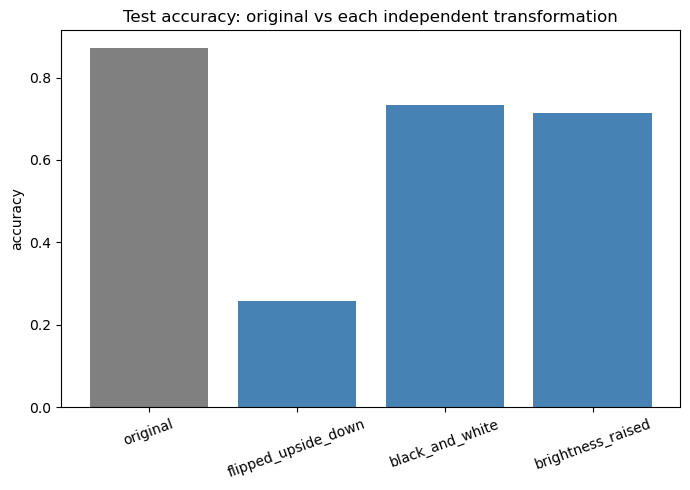

{'original': 0.871, 'flipped_upside_down': 0.257, 'black_and_white': 0.734, 'brightness_raised': 0.714}


In [10]:
original_acc = meta["correct"].mean() if "correct" in meta.columns else None

accs = {"original": original_acc} if original_acc is not None else {}
accs.update({name: res["correct"].mean() for name, res in results_by_transform.items()})

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(accs.keys(), accs.values(), color=["gray", "steelblue", "steelblue", "steelblue"][:len(accs)])
ax.set_ylabel("accuracy")
ax.set_title("Test accuracy: original vs each independent transformation")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(accs)